In [87]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures,OneHotEncoder
from sklearn.metrics import mean_absolute_error
from scipy.special import expit,softmax # expit : 이진분류함수 , softmax : 다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline



In [88]:
#데이터 불러오기
fish = pd.read_csv('data/fish_logistic.csv')
fish.head()

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.5200,4.0200
1,Bream,290.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,26.5,31.1,12.3778,4.6961
3,Bream,363.0,29.0,33.5,12.7300,4.4555
4,Bream,430.0,29.0,34.0,12.4440,5.1340


In [89]:
fish.info()
fish.describe()
fish.shape

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Species   159 non-null    str    
 1   Weight    159 non-null    float64
 2   Length    159 non-null    float64
 3   Diagonal  159 non-null    float64
 4   Height    159 non-null    float64
 5   Width     159 non-null    float64
dtypes: float64(5), str(1)
memory usage: 7.6 KB


(159, 6)

In [90]:
fish.columns

Index(['Species', 'Weight', 'Length', 'Diagonal', 'Height', 'Width'], dtype='str')

In [91]:
data = fish[fish.columns[1:]].values
label = fish['Species'].values
train_data,test_data,train_label,test_label = train_test_split(data,label)


In [92]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [93]:
c_list = [0.0001,0.001,0.01,0.1,1,10,100,1000]
train_score = []
test_score = []
for i in c_list : 
    lr  = LogisticRegression(C=i,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))


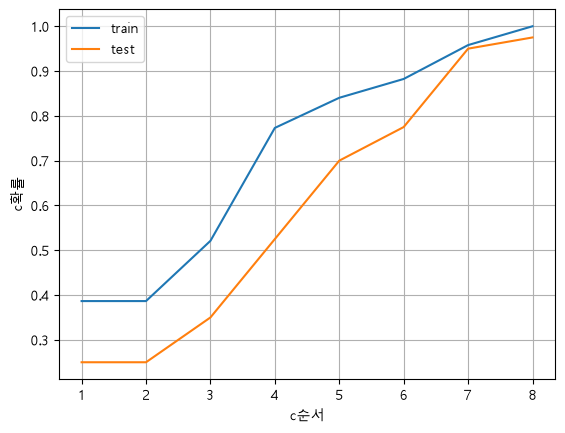

In [94]:
list1 = list(range(1,9))
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('c순서')
plt.ylabel('c확률')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [95]:
print('train정확도 : ',lr.score(train_scaled,train_label))
print('test정확도 : ',lr.score(test_scaled,test_label))

train정확도 :  1.0
test정확도 :  0.975


In [96]:
#실제입력받아 예측하시오.
predict = lr.predict(test_scaled[:1])
print('분류생선 : ',predict)
proba = lr.predict_proba(test_scaled[:1])
print(lr.classes_)

if predict[0] =='Bream':
    result = proba[0][0]
elif predict[0] =='Parkki':
    result = proba[0][1]
elif predict[0] =='Perch':
    result = proba[0][2]
elif predict[0] =='Pike':
    result = proba[0][3]
elif predict[0] =='Roach':
    result = proba[0][4]
elif predict[0] =='Smelt':
    result = proba[0][5]
elif predict[0] =='Whitefish':
    result = proba[0][6]


print('확률 : ',result)


분류생선 :  ['Pike']
['Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']
확률 :  0.9823841541688971


In [99]:
proba = lr.predict_proba(test_scaled[:1])
proba
decisions = lr.decision_function(test_scaled[:1])
decisions
soft1 = softmax(decisions,axis=1)
print(np.round(soft1,decimals=3))
print(lr.classes_)

[[0.    0.    0.003 0.982 0.    0.015 0.   ]]
['Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']


In [ ]:
# 새로운 데이터를 분류
# 1.정규화
# 2.데이터 predict
# 3.